## 1. Problem Definition

**Dữ liệu:** [Women's E-Commerce Clothing Reviews](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews), được công bố trên Kaggle. Bộ dữ liệu gồm 23.486 đánh giá sản phẩm thời trang nữ và các biến chính: `Age`, `Title`, `Review Text`, `Rating`, `Recommended IND`, `Division Name`, `Department Name` và `Class Name`.

**Bài toán:** phân loại nhị phân.
- **Input:** nội dung đánh giá tạo bằng cách ghép `Title` và `Review Text`. Thí nghiệm mở rộng bổ sung `Age` và các biến phân loại sản phẩm.
- **Label:** `Recommended IND`, trong đó 1 là khách hàng đề xuất sản phẩm và 0 là không đề xuất.

**Các vấn đề phương pháp luận**
1. **Mất cân bằng lớp:** khoảng 82,2% mẫu thuộc lớp 1 và 17,8% thuộc lớp 0. Vì vậy, Accuracy không đủ để đánh giá; nghiên cứu sử dụng thêm Macro-F1, F1-score và Recall của lớp 0.
2. **Rò rỉ mục tiêu:** không sử dụng `Rating` vì biến này có quan hệ mạnh với `Recommended IND` và có thể làm bài toán trở nên tầm thường.
3. **Biểu diễn văn bản:** nội dung đánh giá được chuyển thành vector số bằng TF-IDF trước khi huấn luyện mô hình.

**Mô hình:** Logistic Regression, Multinomial Naive Bayes và XGBoost.

**Quy trình:** chuẩn bị dữ liệu -> biểu diễn TF-IDF -> huấn luyện mô hình -> tuning bằng Stratified K-Fold cross-validation -> đánh giá trên tập test -> phân tích lỗi và hạn chế.

## 2. Theoretical Background

### 2.1 TF-IDF Text Representation

Các mô hình học máy cần dữ liệu đầu vào ở dạng số. Mỗi đánh giá được biểu diễn thành một vector trên không gian từ vựng.

- **Bag-of-Words:** biểu diễn mỗi từ bằng số lần xuất hiện và không xét thứ tự từ.
- **n-gram:** biểu diễn các chuỗi liên tiếp gồm một hoặc nhiều từ. Bigram như `not good` giữ lại một phần ngữ cảnh, nhưng làm tăng đáng kể số chiều đặc trưng.
- **TF-IDF:** giảm trọng số của các từ xuất hiện trong nhiều văn bản và tăng trọng số của các từ có tính phân biệt:

$$\text{tfidf}(t,d)=\text{tf}(t,d)\times \text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+n}{1+\text{df}(t)}+1$$

Trong đó, $n$ là số văn bản và $\text{df}(t)$ là số văn bản chứa từ $t$. Đây là công thức có làm trơn được sử dụng mặc định trong scikit-learn. Các vector sau đó được chuẩn hóa theo chuẩn L2.

Tham số `sublinear_tf=True` thay thế tần suất từ $\text{tf}$ bằng $1+\ln(\text{tf})$, giúp giảm ảnh hưởng của các từ lặp lại nhiều lần. `min_df` loại bỏ các từ hiếm, còn `max_features` giới hạn kích thước từ vựng.

Để tránh rò rỉ dữ liệu, vectorizer được đặt trong `Pipeline`. Trong quá trình cross-validation, từ vựng và trọng số IDF chỉ được học trên phần train của từng fold.

### 2.2 Logistic Regression

Logistic Regression ước lượng xác suất một mẫu thuộc lớp 1 bằng hàm sigmoid:

$$P(y=1\mid x)=\sigma(w^\top x+b)=\frac{1}{1+e^{-(w^\top x+b)}}$$

Mô hình dự đoán lớp 1 khi $P(y=1\mid x)\geq 0,5$. Với điều chuẩn L2 và trọng số mẫu, hàm mục tiêu có dạng:

$$\min_{w,b}\ \frac{1}{2}\lVert w\rVert_2^2+C\sum_i s_i\left[-y_i\ln p_i-(1-y_i)\ln(1-p_i)\right]$$

Trong đó, $C$ là nghịch đảo của cường độ điều chuẩn. Giá trị $C$ nhỏ tạo ra điều chuẩn mạnh hơn. Tham số `class_weight='balanced'` gán trọng số lớn hơn cho lớp thiểu số. Solver `lbfgs` phù hợp với điều chuẩn L2 và dữ liệu TF-IDF dạng thưa.

Hệ số của đặc trưng $j$ cho biết mức đóng góp của đặc trưng đó vào hàm quyết định: hệ số dương hỗ trợ lớp 1, còn hệ số âm hỗ trợ lớp 0.

### 2.3 Multinomial Naive Bayes

Multinomial Naive Bayes áp dụng định lý Bayes với giả định độc lập có điều kiện giữa các từ khi đã biết lớp:

$$P(c\mid d)\propto P(c)\prod_t P(t\mid c)^{x_t}$$

Dạng tương đương theo log-posterior là:

$$\hat c=\arg\max_c\left[\ln P(c)+\sum_t x_t\ln P(t\mid c)\right]$$

Với kỹ thuật làm trơn cộng, xác suất có điều kiện của từ $t$ trong lớp $c$ được ước lượng bởi:

$$\hat\theta_{ct}=\frac{N_{ct}+\alpha}{N_c+\alpha|V|}$$

Trong đó, $\alpha>0$ giúp tránh xác suất bằng 0, $N_{ct}$ là tổng giá trị đặc trưng của từ $t$ trong lớp $c$, còn $|V|$ là kích thước từ vựng. `fit_prior=True` ước lượng xác suất tiên nghiệm theo phân bố lớp; `False` sử dụng xác suất tiên nghiệm đồng đều.

Mặc dù mô hình được xây dựng cho đặc trưng dạng đếm, các giá trị TF-IDF không âm vẫn có thể được sử dụng trong thực tế. Mô hình có chi phí tính toán thấp, nhưng giả định độc lập không phản ánh đầy đủ quan hệ ngữ nghĩa giữa các từ.

### 2.4 XGBoost

XGBoost là phương pháp gradient boosting, xây dựng một tổ hợp cộng dồn gồm nhiều cây quyết định. Ở vòng lặp $t$, một cây mới được huấn luyện để cải thiện dự đoán hiện tại:

$$\hat y_i^{(t)}=\hat y_i^{(t-1)}+\eta f_t(x_i)$$

Đối với phân loại nhị phân, hàm mục tiêu gồm logistic loss và thành phần điều chuẩn nhằm kiểm soát độ phức tạp của cây:

$$\mathcal L=\sum_i\ell(y_i,\hat y_i)+\sum_k\Omega(f_k),\qquad \Omega(f)=\gamma T+\frac{1}{2}\lambda\lVert w\rVert^2$$

Trong đó, $T$ là số lá và $w$ là vector trọng số của các lá. XGBoost sử dụng khai triển Taylor bậc hai. Với một lá chứa tập mẫu $I_j$, trọng số tối ưu được tính bởi:

$$w_j^*=-\frac{G_j}{H_j+\lambda}$$

Trong công thức trên, $G_j=\sum_{i\in I_j}g_i$ và $H_j=\sum_{i\in I_j}h_i$ lần lượt là tổng gradient và Hessian.

Các siêu tham số chính gồm:
- `n_estimators` và `learning_rate`: điều khiển số lượng và mức đóng góp của các cây.
- `max_depth` và `min_child_weight`: kiểm soát độ phức tạp của cây và hạn chế overfitting.
- `subsample` và `colsample_bytree`: lấy mẫu ngẫu nhiên theo quan sát và theo đặc trưng.
- `scale_pos_weight`: điều chỉnh ảnh hưởng của mất cân bằng lớp. Trong dữ liệu này, lớp 1 là lớp đa số nên tham số được đặt bằng $n_{neg}/n_{pos}$.

Thuật toán histogram (`tree_method='hist'`) tăng tốc quá trình tìm điểm chia. GPU được sử dụng khi môi trường hỗ trợ `device='cuda'`, còn quá trình tạo đặc trưng TF-IDF vẫn chạy trên CPU. Do TF-IDF tạo ra dữ liệu thưa và nhiều chiều, mô hình tuyến tính vẫn có thể cạnh tranh với XGBoost.

### 2.5 Evaluation Metrics for Imbalanced Classification

Với mỗi lớp, Precision, Recall và F1-score được xác định như sau:

$$\text{Precision}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},\qquad F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

Trong dữ liệu mất cân bằng, Accuracy có thể gây hiểu nhầm vì mô hình luôn dự đoán lớp 1 vẫn đạt khoảng 0,822.

- **F1-score và Recall của lớp 0:** đánh giá khả năng nhận diện các đánh giá không đề xuất sản phẩm.
- **Macro-F1:** là trung bình không trọng số của F1-score trên hai lớp:

$$\text{Macro-F1}=\frac{1}{2}\left(F_1^{(0)}+F_1^{(1)}\right)$$

Macro-F1 được sử dụng làm chỉ số chính để lựa chọn mô hình. ROC-AUC đánh giá chất lượng xếp hạng của xác suất dự đoán và không phụ thuộc vào một ngưỡng phân loại cố định.

### 2.6 Cross-Validation and Hyperparameter Tuning

Dữ liệu được chia thành tập train và test theo tỷ lệ 80:20 với phương pháp stratification. Tập test chỉ được sử dụng cho đánh giá cuối cùng và không tham gia vào quá trình lựa chọn mô hình.

**Stratified K-Fold cross-validation** chia tập train thành $K$ fold với tỷ lệ lớp được duy trì. Mỗi fold lần lượt được dùng làm tập validation; điểm trung bình được sử dụng để so sánh các cấu hình tham số.

**RandomizedSearchCV** lấy mẫu ngẫu nhiên các tổ hợp tham số từ những phân phối đã định nghĩa. Phương pháp này phù hợp khi không gian tìm kiếm lớn và chỉ một số tham số có ảnh hưởng đáng kể đến hiệu năng. Phân phối log-uniform được dùng cho các tham số như `C`, `alpha` và `learning_rate`.

Quá trình tìm kiếm tối ưu `f1_macro`. Sau khi chọn cấu hình tốt nhất, `refit=True` huấn luyện lại mô hình trên toàn bộ tập train. Việc đặt TF-IDF và mô hình phân loại trong cùng một `Pipeline` giúp ngăn dữ liệu validation ảnh hưởng đến bước trích xuất đặc trưng.

Overfitting được nhận biết khi điểm trên tập train cao hơn đáng kể so với điểm validation hoặc test. Các tham số kiểm soát gồm `C` của Logistic Regression, `alpha` của Naive Bayes, cùng độ sâu cây, learning rate, child weight và tỷ lệ lấy mẫu của XGBoost.

## 3. Implementation

### 3.1 Library Import and Device Detection

XGBoost uses GPU acceleration when CUDA is available. Logistic Regression and Multinomial Naive Bayes are executed on the CPU.

In [10]:
# %pip install -q scikit-learn xgboost pandas matplotlib seaborn

import os, shutil, time, warnings
import pandas as pd
import numpy as np
from joblib import Memory
from scipy.stats import loguniform, randint, uniform
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier

try:
    import torch
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
except ModuleNotFoundError:
    device = 'cuda' if shutil.which('nvidia-smi') else 'cpu'

device_name = device.type if hasattr(device, 'type') else device
print(f'Device: {device_name}')

Device: cuda


### 3.2 Data Loading

In [11]:
csv_path = os.path.join(os.getcwd(), "Womens Clothing E-Commerce Reviews.csv")
if not os.path.exists(csv_path):
    raise FileNotFoundError("File CSV Not Found: " + csv_path)

df = pd.read_csv(csv_path)
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]   # bo cot index thua
print(df.head())
print(df.shape)

   Clothing ID  Age                    Title  \
0          767   33                      NaN   
1         1080   34                      NaN   
2         1077   60  Some major design flaws   
3         1049   50         My favorite buy!   
4          847   47         Flattering shirt   

                                         Review Text  Rating  Recommended IND  \
0  Absolutely wonderful - silky and sexy and comf...       4                1   
1  Love this dress!  it's sooo pretty.  i happene...       5                1   
2  I had such high hopes for this dress and reall...       3                0   
3  I love, love, love this jumpsuit. it's fun, fl...       5                1   
4  This shirt is very flattering to all due to th...       5                1   

   Positive Feedback Count   Division Name Department Name Class Name  
0                        0       Initmates        Intimate  Intimates  
1                        4         General         Dresses    Dresses  
2       

### 3.3 Exploratory Data Analysis

The analysis examines class distribution, missing values, review length, and the relationship between `Rating` and `Recommended IND`.

Tỷ lệ Recommended IND:
Recommended IND
1    0.822
0    0.178
Name: proportion, dtype: float64

Missing values:
Title              3810
Review Text         845
Division Name        14
Department Name      14
Class Name           14
dtype: int64


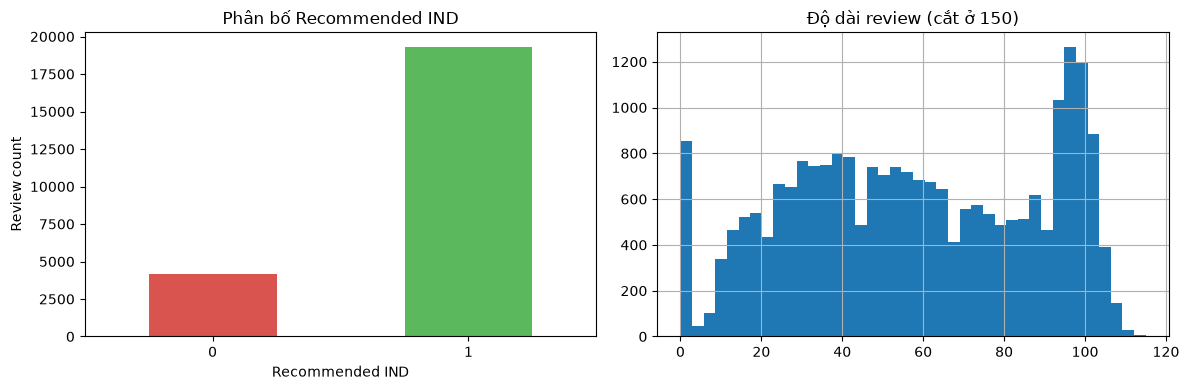

Tỷ lệ recommend theo Rating:


Recommended IND,0,1
Rating,,
1,0.981,0.019
2,0.940,0.060
3,0.586,0.414
4,0.033,0.967
5,0.002,0.998


In [12]:
print('Tỷ lệ Recommended IND:')
print(df['Recommended IND'].value_counts(normalize=True).round(3))
print('\nMissing values:')
print(df.isna().sum()[df.isna().sum() > 0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Recommended IND'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color=['#d9534f', '#5cb85c'])
axes[0].set_title('Phân bố Recommended IND')
axes[0].set_xlabel('Recommended IND'); axes[0].set_ylabel('Review count'); axes[0].tick_params(axis='x', rotation=0)

df['Review Text'].fillna('').str.split().str.len().clip(upper=150).hist(bins=40, ax=axes[1])
axes[1].set_title('Độ dài review (cắt ở 150)')
plt.tight_layout(); plt.show()

print('Tỷ lệ recommend theo Rating:')
pd.crosstab(df['Rating'], df['Recommended IND'], normalize='index').round(3)

### 3.4 Preprocessing and Data Splitting

- Concatenate `Title` and `Review Text` into `text`.
- Replace missing categorical values with `Unknown`.
- Split the data into stratified training and test sets.
- Compute `scale_pos_weight` for XGBoost.

In [13]:
# Tiền xử lý: ghép Title + Review Text, điền giá trị thiếu, chia train/test (stratify), tính scale_pos_weight
df['Title'] = df['Title'].fillna('')
df['Review Text'] = df['Review Text'].fillna('')
df['text'] = df['Title'] + ' ' + df['Review Text']

for ch in ['Division Name', 'Department Name', 'Class Name']:
    df[ch] = df[ch].fillna('Unknown')

y = df['Recommended IND'].astype(int)
X = df[['text', 'Age', 'Division Name', 'Department Name', 'Class Name']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train_text, X_test_text = X_train['text'], X_test['text']

#He so can bang lop
spw = (y_train == 0).sum() / (y_train == 1).sum()

print('Scale pos weight (spw): %.3f' % spw)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Tỷ lệ lớp 1 - train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

Scale pos weight (spw): 0.216
Train: (18788, 5) Test: (4698, 5)
Tỷ lệ lớp 1 - train: 0.822 | test: 0.822


### 3.5 Evaluation Function

All models are evaluated on the same test set using the metrics defined in Section 2.5.

In [14]:
# Hàm lưu kết quả từng mô hình vào dict `results` (chỉ số) và `fitted` (mô hình đã fit) để so sánh về sau
results = {}
fitted = {}

def add_res(name, model, X_eval, y_eval, fit_time):
    y_pred = model.predict(X_eval)
    probs = model.predict_proba(X_eval)[:, 1]
    results[name] = {
        'Model': name,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'F1 (Class 1)': f1_score(y_eval, y_pred, pos_label=1),
        'F1 (Class 0)': f1_score(y_eval, y_pred, pos_label=0),
        'Macro F1': f1_score(y_eval, y_pred, average='macro'),
        'Recall (Class 0)': recall_score(y_eval, y_pred, pos_label=0),
        'ROC_AUC': roc_auc_score(y_eval, probs),
        'Fit Time (s)': round(fit_time, 2)
    }
    fitted[name] = (model, X_eval)

def show_results():
    out = pd.DataFrame(results.values()).sort_values('Macro F1', ascending=False).reset_index(drop=True)
    return out.round(4)

### 3.6 Baseline Models

Baseline models provide a reference for evaluating the effect of hyperparameter tuning.

In [15]:
# Baseline models

def tfidf_base():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

baselines = {
    'LogReg (baseline)': Pipeline([
        ('tfidf', tfidf_base()),
        ('clf', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000)),
    ]),
    'NaiveBayes (baseline)': Pipeline([
        ('tfidf', tfidf_base()),
        ('clf', MultinomialNB(alpha=0.1)),
    ]),
    'XGBoost (baseline)': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=5000)),
        ('clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                              colsample_bytree=0.8, scale_pos_weight=spw, tree_method='hist',
                              eval_metric='logloss', n_jobs=1, random_state=42, device='cuda')),
    ]),
}

for name, pipe in baselines.items():
    t0 = time.time()
    pipe.fit(X_train_text, y_train)
    add_res(name, pipe, X_test_text, y_test, time.time() - t0)

show_results()

,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.32
1,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,6.87
2,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.21


### 3.7 Hyperparameter Tuning

`RandomizedSearchCV` with Stratified K-Fold cross-validation is used to optimize Macro-F1. The reported fit time for tuned models corresponds to refitting the selected estimator; search time is reported separately.

In [16]:
# Hàm tuning chung: RandomizedSearchCV + Stratified K-Fold, tối ưu Macro-F1; n_jobs=-1 cho CPU, n_jobs=1 cho GPU
def run_search(name, pipe, param_dist, n_iter, cv_splits=5, n_jobs=-1):
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42)
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring='f1_macro',
        n_jobs=n_jobs,
        cv=cv,
        verbose=2,
        random_state=42,
        refit=True
    )

    t0 = time.time()
    search.fit(X_train_text, y_train)

    print(f'[{name}] Time: {time.time() - t0:.0f}s')
    print('\n' + '=' * 60)
    print(f'BEST CONFIGURATION: {name}')
    print('=' * 60)
    print(f'Best CV Macro-F1: {search.best_score_:.4f}')
    print('Best parameters:')
    for parameter, value in search.best_params_.items():
        print(f'  {parameter}: {value}')
    print('=' * 60)

    add_res(name, search.best_estimator_, X_test_text, y_test, search.refit_time_)
    return search

#### Logistic Regression

In [17]:
# Tuning Logistic Regression (CPU, song song n_jobs=-1)
lr_pipe = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000))
])

lr_params = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_features': [None, 20000, 50000],
    'tfidf__sublinear_tf': [True, False],
    'clf__C': loguniform(1e-2, 1e2)
}

lr_search = run_search('LogReg (tuned)', lr_pipe, lr_params, n_iter=20)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END clf__C=0.017073967431528128, tfidf__max_features=None, tfidf__min_df=5, tfidf__ngram_range=(1, 3), tfidf__sublinear_tf=False; total time=   4.2s
[CV] END clf__C=0.017073967431528128, tfidf__max_features=None, tfidf__min_df=5, tfidf__ngram_range=(1, 3), tfidf__sublinear_tf=False; total time=   4.4s
[CV] END clf__C=0.31489116479568624, tfidf__max_features=None, tfidf__min_df=3, tfidf__ngram_range=(1, 3), tfidf__sublinear_tf=False; total time=   4.6s
[CV] END clf__C=0.31489116479568624, tfidf__max_features=None, tfidf__min_df=3, tfidf__ngram_range=(1, 3), tfidf__sublinear_tf=False; total time=   4.6s
[CV] END clf__C=0.31489116479568624, tfidf__max_features=None, tfidf__min_df=3, tfidf__ngram_range=(1, 3), tfidf__sublinear_tf=False; total time=   4.8s
[CV] END clf__C=0.31489116479568624, tfidf__max_features=None, tfidf__min_df=3, tfidf__ngram_range=(1, 3), tfidf__sublinear_tf=False; total time=   4.8s
[CV] END clf__C=0.

#### Multinomial Naive Bayes

In [18]:
# Tuning Multinomial Naive Bayes (CPU, song song n_jobs=-1)
nb_pipe = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())    
])

nb_params = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_features': [None, 20000, 50000],
    'tfidf__sublinear_tf': [True, False],
    'clf__alpha': loguniform(1e-3, 2),
    'clf__fit_prior': [True, False]
}

nb_search = run_search('NaiveBayes (tuned)', nb_pipe, nb_params, n_iter=20)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END clf__alpha=0.017233288831716688, clf__fit_prior=True, tfidf__max_features=50000, tfidf__min_df=3, tfidf__ngram_range=(1, 1), tfidf__sublinear_tf=True; total time=   0.9s
[CV] END clf__alpha=0.017233288831716688, clf__fit_prior=True, tfidf__max_features=50000, tfidf__min_df=3, tfidf__ngram_range=(1, 1), tfidf__sublinear_tf=True; total time=   0.9s
[CV] END clf__alpha=0.017233288831716688, clf__fit_prior=True, tfidf__max_features=50000, tfidf__min_df=3, tfidf__ngram_range=(1, 1), tfidf__sublinear_tf=True; total time=   1.0s
[CV] END clf__alpha=0.017233288831716688, clf__fit_prior=True, tfidf__max_features=50000, tfidf__min_df=3, tfidf__ngram_range=(1, 1), tfidf__sublinear_tf=True; total time=   1.1s
[CV] END clf__alpha=0.017233288831716688, clf__fit_prior=True, tfidf__max_features=50000, tfidf__min_df=3, tfidf__ngram_range=(1, 1), tfidf__sublinear_tf=True; total time=   1.1s
[CV] END clf__alpha=0.012635200422215125, c

#### XGBoost

The XGBoost search runs on the GPU with `device='cuda'` and `n_jobs=1`. Pipeline caching reduces repeated TF-IDF transformations across parameter configurations.

In [19]:
# Tuning XGBoost trên GPU: n_jobs=1 để các fit chạy tuần tự (mỗi fit dùng GPU); Memory cache kết quả TF-IDF
memory = Memory(os.path.join(os.getcwd(), '.tfidf_cache'), verbose=0)

xgb_pipe = Pipeline(
    [
        ('tfidf', TfidfVectorizer(sublinear_tf=True, dtype=np.float32)),
        ('clf', XGBClassifier(scale_pos_weight=spw, tree_method='hist', device='cuda', eval_metric='logloss', n_jobs=1, random_state=42)),
    ], 
    memory=memory
)

xgb_params = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [2, 3],
    'tfidf__max_features': [3000, 5000, 10000],
    'clf__max_depth': randint(3, 9),
    'clf__n_estimators': randint(200, 600),
    'clf__learning_rate': loguniform(0.03, 0.3),
    'clf__subsample': uniform(0.6, 0.4),
    'clf__colsample_bytree': uniform(0.4, 0.6),
    'clf__min_child_weight': randint(1, 8)
}

xgb_search = run_search('XGBoost (tuned)', xgb_pipe, xgb_params, n_iter=12, cv_splits=3, n_jobs=1)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
[CV] END clf__colsample_bytree=0.6247240713084175, clf__learning_rate=0.2678154091306088, clf__max_depth=5, clf__min_child_weight=5, clf__n_estimators=220, clf__subsample=0.6624074561769746, tfidf__max_features=10000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=   1.1s
[CV] END clf__colsample_bytree=0.6247240713084175, clf__learning_rate=0.2678154091306088, clf__max_depth=5, clf__min_child_weight=5, clf__n_estimators=220, clf__subsample=0.6624074561769746, tfidf__max_features=10000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=   1.1s
[CV] END clf__colsample_bytree=0.6247240713084175, clf__learning_rate=0.2678154091306088, clf__max_depth=5, clf__min_child_weight=5, clf__n_estimators=220, clf__subsample=0.6624074561769746, tfidf__max_features=10000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=   1.1s
[CV] END clf__colsample_bytree=0.6755493351795203, clf__learning_rate=0.06468891483556281, clf__

In [20]:
# Cache TF-IDF chỉ trong lúc tuning; xóa giải phóng ổ đĩa
memory.clear(warn=False)

### 3.8 XGBoost with Metadata

This experiment adds `Age`, `Division Name`, `Department Name`, and `Class Name` to the text representation.

In [21]:
# XGBoost + metadata: ghép TF-IDF của văn bản với Age và 3 cột phân loại (one-hot)
xgb_best = {k.replace('clf__', ''): v for k, v in xgb_search.best_params_.items() if k.startswith('clf__')}
tf_best = {k.replace('tfidf__', ''): v for k, v in xgb_search.best_params_.items() if k.startswith('tfidf__')}

meta_pre = ColumnTransformer([
    ('tfidf', TfidfVectorizer(sublinear_tf=True, **tf_best), 'text'),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['Division Name', 'Department Name', 'Class Name']),
    ('age', 'passthrough', ['Age']),
])
xgb_meta = Pipeline([
    ('pre', meta_pre),
    ('clf', XGBClassifier(**xgb_best, scale_pos_weight=spw, tree_method='hist', device='cuda', eval_metric='logloss', n_jobs=1, random_state=42)),
])

t0 = time.time()
xgb_meta.fit(X_train, y_train)
add_res('XGBoost + metadata', xgb_meta, X_test, y_test, time.time() - t0)
show_results()

,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,LogReg (tuned),0.9106,0.9450,0.7605,0.8528,0.7988,0.9478,2.86
1,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.32
2,XGBoost (tuned),0.9059,0.9418,0.7553,0.8485,0.8168,0.9444,8.91
3,XGBoost + metadata,0.9051,0.9413,0.7517,0.8465,0.8084,0.9443,10.40
4,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,6.87
5,NaiveBayes (tuned),0.9017,0.9407,0.7116,0.8262,0.6826,0.9445,3.76
6,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.21


In [32]:
# Stream the best XGBoost training history to TensorBoard after every boosting round
from sklearn.base import clone
from tensorboardX import SummaryWriter
from xgboost.callback import TrainingCallback

class TensorBoardCallback(TrainingCallback):
    def __init__(self, writer):
        self.writer = writer

    def after_iteration(self, model, epoch, evals_log):
        for split_name, metrics_dict in evals_log.items():
            for metric_name, values in metrics_dict.items():
                self.writer.add_scalar(f'{split_name}/{metric_name}', values[-1], epoch)
        self.writer.flush()
        return False

best_xgb = xgb_search.best_estimator_
tfidf_best = best_xgb.named_steps['tfidf']

X_train_tfidf = tfidf_best.transform(X_train_text)
X_test_tfidf = tfidf_best.transform(X_test_text)

log_dir = os.path.join(os.getcwd(), 'runs', 'xgboost')
if os.path.exists(log_dir):
    shutil.rmtree(log_dir)
os.makedirs(log_dir, exist_ok=True)

writer = SummaryWriter(log_dir=log_dir)
xgb_logged = clone(best_xgb.named_steps['clf'])
xgb_logged.set_params(
    eval_metric='logloss',
    device='cuda',
    n_jobs=1,
    callbacks=[TensorBoardCallback(writer)]
)

xgb_logged.fit(
    X_train_tfidf,
    y_train,
    eval_set=[(X_train_tfidf, y_train), (X_test_tfidf, y_test)],
    verbose=False
)
writer.close()

print(f'Previous TensorBoard history cleared.')
print(f'TensorBoard logs updated after each boosting round: {log_dir}')
print(f'Boosting rounds logged: {xgb_logged.n_estimators}')

Previous TensorBoard history cleared.
TensorBoard logs updated after each boosting round: /home/bao/WorkSpace/BTL_ML261/runs/xgboost
Boosting rounds logged: 566


In [31]:
# Launch TensorBoard inside the notebook
%load_ext tensorboard
%tensorboard --logdir runs/xgboost

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 32921), started 0:06:34 ago. (Use '!kill 32921' to kill it.)

## 4. Experimental Results

### 4.1 Model Comparison

,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,LogReg (tuned),0.9106,0.9450,0.7605,0.8528,0.7988,0.9478,2.86
1,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.32
2,XGBoost (tuned),0.9059,0.9418,0.7553,0.8485,0.8168,0.9444,8.91
3,XGBoost + metadata,0.9051,0.9413,0.7517,0.8465,0.8084,0.9443,10.40
4,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,6.87
5,NaiveBayes (tuned),0.9017,0.9407,0.7116,0.8262,0.6826,0.9445,3.76
6,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.21


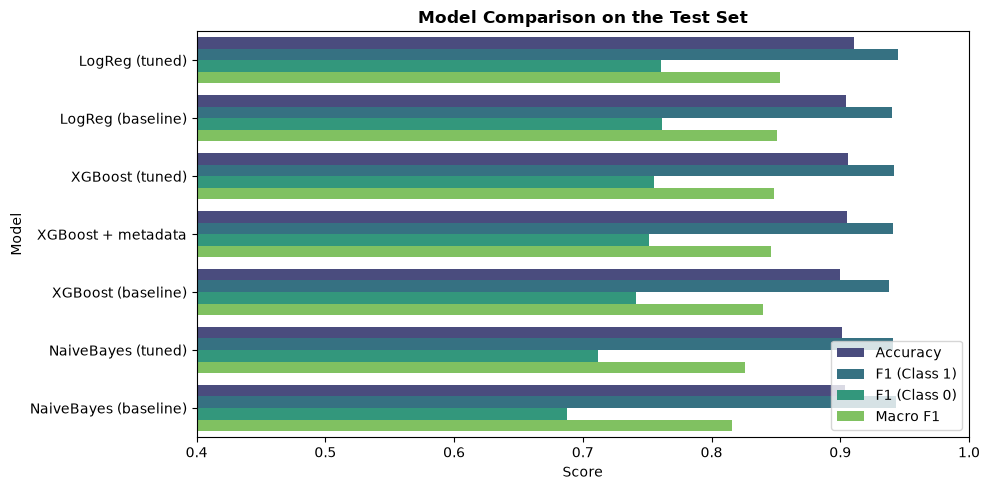

In [24]:
# Bảng kết quả + biểu đồ so sánh
results_df = show_results()
display(results_df)

metrics = ['Accuracy', 'F1 (Class 1)', 'F1 (Class 0)', 'Macro F1']
plot_df = results_df.melt(id_vars='Model', value_vars=metrics, var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, y='Model', x='Score', hue='Metric', palette='viridis')
plt.xlim(0.4, 1.0)
plt.title('Model Comparison on the Test Set', fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 4.2 Overfitting Analysis

The train-test Macro-F1 gap is used as an indicator of potential overfitting. Training performance is generally optimistic because the model has seen the training observations.

In [25]:
# Kiểm tra overfitting: so sánh Macro-F1 trên tập train và tập test
rows = []
for name, (model, X_eval) in fitted.items():
    X_tr = X_train if name.endswith('metadata') else X_train_text
    rows.append({
        'Model': name,
        'Macro F1 (train)': f1_score(y_train, model.predict(X_tr), average='macro'),
        'Macro F1 (test)': f1_score(y_test, model.predict(X_eval), average='macro'),
    })
gap_df = pd.DataFrame(rows)
gap_df['Gap (train - test)'] = gap_df['Macro F1 (train)'] - gap_df['Macro F1 (test)']
display(gap_df.sort_values('Gap (train - test)', ascending=False).round(4).reset_index(drop=True))

,Model,Macro F1 (train),Macro F1 (test),Gap (train - test)
0,NaiveBayes (baseline),0.9557,0.8156,0.1401
1,LogReg (tuned),0.9562,0.8528,0.1034
2,XGBoost + metadata,0.9330,0.8465,0.0866
3,XGBoost (baseline),0.9251,0.8396,0.0855
4,XGBoost (tuned),0.9327,0.8485,0.0842
5,NaiveBayes (tuned),0.8904,0.8262,0.0642
6,LogReg (baseline),0.9068,0.8510,0.0558


### 4.3 Confusion Matrices and Classification Reports

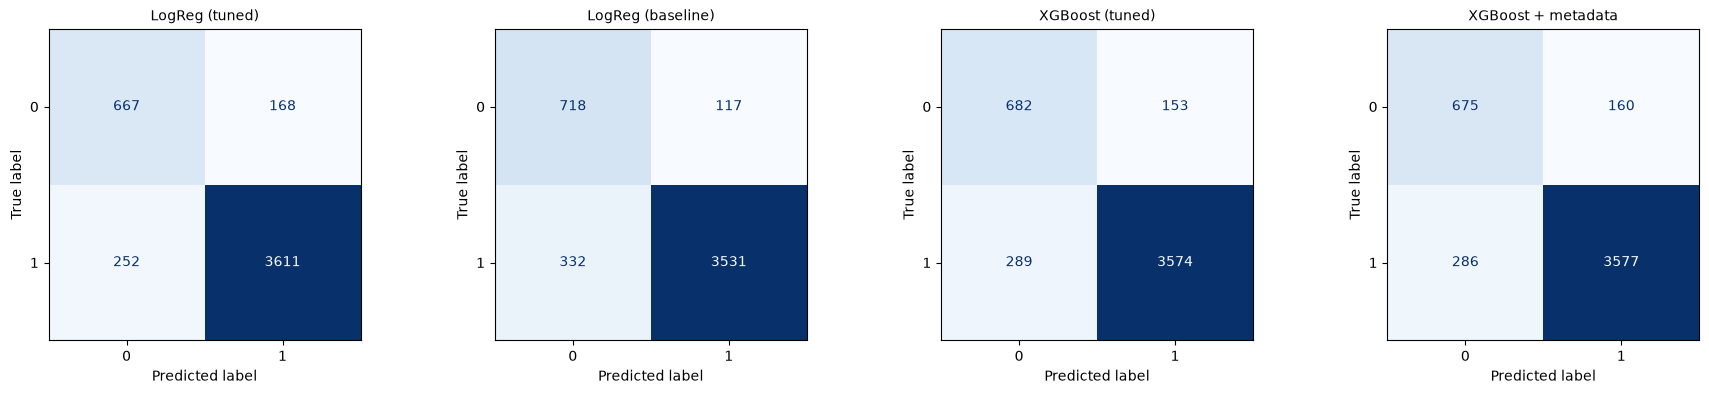

Best model (Macro F1): LogReg (tuned)

                     precision    recall  f1-score   support

Không recommend (0)       0.73      0.80      0.76       835
      Recommend (1)       0.96      0.93      0.95      3863

           accuracy                           0.91      4698
          macro avg       0.84      0.87      0.85      4698
       weighted avg       0.91      0.91      0.91      4698



In [26]:
# Confusion matrix của 4 mô hình tốt nhất theo Macro-F1
top_names = results_df['Model'].head(4).tolist()
fig, axes = plt.subplots(1, len(top_names), figsize=(4.5 * len(top_names), 4))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, top_names):
    model, X_eval = fitted[name]
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_eval), display_labels=['0', '1'], cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

best_name = results_df.loc[0, 'Model']
model, X_eval = fitted[best_name]
print(f'Best model (Macro F1): {best_name}\n')
print(classification_report(y_test, model.predict(X_eval), target_names=['Không recommend (0)', 'Recommend (1)']))

### 4.4 Most Influential Terms

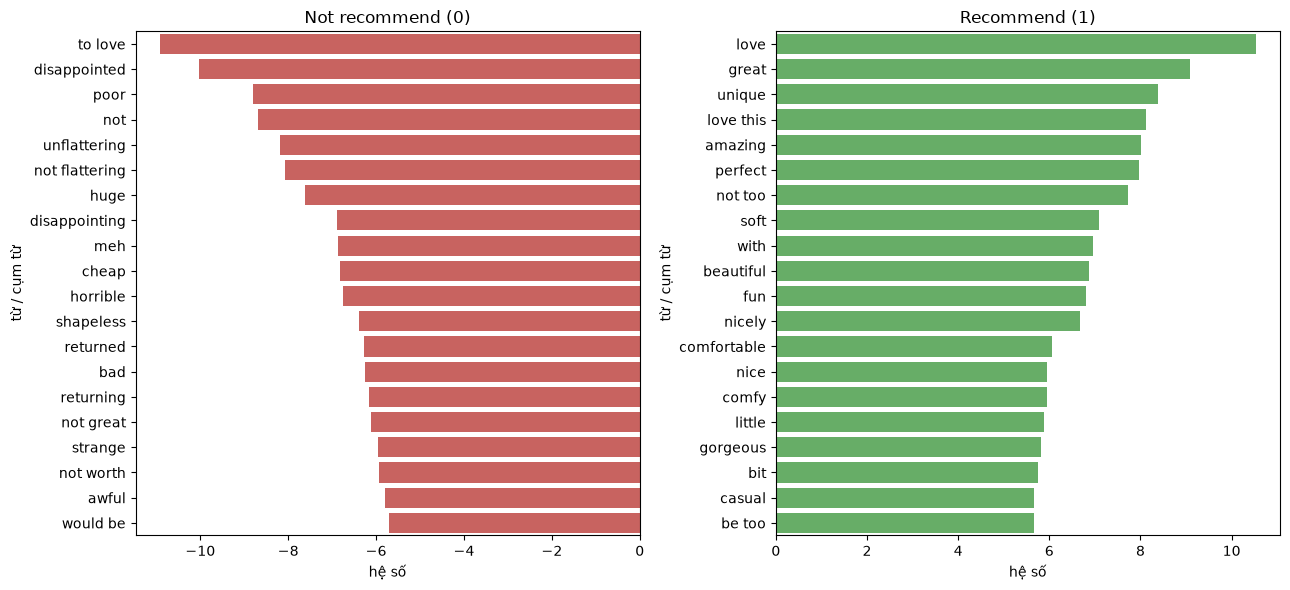

In [27]:
# Hệ số của Logistic Regression: hệ số dương -> đẩy về recommend (1), hệ số âm -> đẩy về không recommend (0)
best_lr = lr_search.best_estimator_
vec, clf = best_lr.named_steps['tfidf'], best_lr.named_steps['clf']
feat = np.array(vec.get_feature_names_out())
coef = clf.coef_[0]
order = np.argsort(coef)

top_neg = pd.DataFrame({'từ / cụm từ': feat[order[:20]], 'hệ số': coef[order[:20]]})
top_pos = pd.DataFrame({'từ / cụm từ': feat[order[-20:][::-1]], 'hệ số': coef[order[-20:][::-1]]})

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
sns.barplot(data=top_neg, y='từ / cụm từ', x='hệ số', color='#d9534f', ax=axes[0])
axes[0].set_title('Not recommend (0)')
sns.barplot(data=top_pos, y='từ / cụm từ', x='hệ số', color='#5cb85c', ax=axes[1])
axes[1].set_title('Recommend (1)')
plt.tight_layout(); plt.show()

### 4.5 Error Analysis

In [28]:
# Phân tích lỗi: các review mô hình đoán sai với độ tự tin cao nhất
best_name = results_df.loc[0, 'Model']
model, X_eval = fitted[best_name]
proba = model.predict_proba(X_eval)[:, 1]

err = pd.DataFrame({
    'text': X_test['text'].values,
    'thực tế': y_test.values,
    'dự đoán': model.predict(X_eval),
    'P(recommend)': proba.round(3),
})

print(f'Mô hình: {best_name}')
print('\n=== Thực tế KHÔNG recommend nhưng mô hình đoán recommend ===')
display(err[(err['thực tế'] == 0) & (err['dự đoán'] == 1)].sort_values('P(recommend)', ascending=False).head(8))

print('\n=== Thực tế recommend nhưng mô hình đoán KHÔNG recommend ===')
display(err[(err['thực tế'] == 1) & (err['dự đoán'] == 0)].sort_values('P(recommend)').head(8))

Mô hình: LogReg (tuned)

=== Thực tế KHÔNG recommend nhưng mô hình đoán recommend ===


,text,thực tế,dự đoán,P(recommend)
21,Love this dress I also have this dress in 3/4 ...,0,1,1.000
3374,Comfy This shirt is like the best worn in flan...,0,1,1.000
2540,Classic I tried this top on with a pair of whi...,0,1,0.999
2851,Cute pant Unfortunately i had to size down twi...,0,1,0.998
2214,Sale find I bought this in navy and love the m...,0,1,0.998
3768,Beautiful I've wondered abt this swtr but hesi...,0,1,0.996
796,"Very pretty, romantic",0,1,0.992
4150,Stunning This jumpsuit runs large so i sized d...,0,1,0.987



=== Thực tế recommend nhưng mô hình đoán KHÔNG recommend ===


,text,thực tế,dự đoán,P(recommend)
1733,Much thinner I was so excited to receive this ...,1,0,0.001
4222,Strange shape I'm not really sure what the des...,1,0,0.001
1111,Not for me I ordered these with high hopes. i ...,1,0,0.005
1174,Cute but... I ordered this top because i liked...,1,0,0.007
4548,"Great dress, poor stitching After the second w...",1,0,0.007
899,I recommend with caveats I splurged on this to...,1,0,0.007
77,Terrible cut These look nothing like the pictu...,1,0,0.008
3407,Front black mesh at top pokes out at sides I a...,1,0,0.008


### 4.6 Exported Results

In [29]:
# Save results and train/test indices in the demo folder
output_dir = os.path.join(os.getcwd(), 'demo')
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(os.path.join(output_dir, 'ml_results.csv'), index=False)
pd.Series(X_train.index, name='index').to_csv(os.path.join(output_dir, 'train_index.csv'), index=False)
pd.Series(X_test.index, name='index').to_csv(os.path.join(output_dir, 'test_index.csv'), index=False)

print(f'Saved CSV files to: {output_dir}')
print('  - ml_results.csv')
print('  - train_index.csv')
print('  - test_index.csv')

Saved CSV files to: /home/bao/WorkSpace/BTL_ML261/demo
  - ml_results.csv
  - train_index.csv
  - test_index.csv


## 5. Discussion, Limitations, and Conclusion

**Nhận xét**
1. Accuracy có sự khác biệt nhỏ giữa các mô hình, trong khi Macro-F1 và Recall của lớp 0 phản ánh rõ hơn ảnh hưởng của mất cân bằng lớp.
2. Logistic Regression sau tuning đạt Macro-F1 cao nhất và có chi phí tính toán thấp. XGBoost cho kết quả cạnh tranh nhưng không vượt mô hình tuyến tính trên dữ liệu TF-IDF thưa.
3. Chênh lệch giữa các mô hình dẫn đầu là nhỏ và có thể phụ thuộc vào cách chia dữ liệu. Cần đánh giá lặp lại để có kết luận đáng tin cậy hơn.
4. Việc bổ sung metadata không cải thiện kết quả của XGBoost trong thí nghiệm này. Cần thực hiện thêm các thí nghiệm có kiểm soát trước khi khái quát hóa kết luận.

**Hạn chế**
- Chỉ sử dụng một lần chia train-test; chưa tính khoảng tin cậy hoặc đánh giá lặp lại.
- Số vòng tìm kiếm ngẫu nhiên và không gian siêu tham số còn giới hạn.
- TF-IDF không biểu diễn tốt ngữ cảnh dài, quan hệ phủ định hoặc cách diễn đạt mỉa mai.
- Ngưỡng quyết định được cố định ở 0,5 và chưa được tối ưu theo một mục tiêu cụ thể.
- Dữ liệu chỉ đại diện cho một nhà bán lẻ nên khả năng khái quát sang miền khác còn hạn chế.

**Hướng phát triển:** so sánh các mô hình truyền thống với BiLSTM, GRU, CNN một chiều và các mô hình transformer trên cùng tập train-test.

**Tài liệu tham khảo**
- Bộ dữ liệu: Women's E-Commerce Clothing Reviews, Kaggle (nicapotato).
- Pedregosa và cộng sự (2011), *Scikit-learn: Machine Learning in Python*, JMLR 12.
- Chen và Guestrin (2016), *XGBoost: A Scalable Tree Boosting System*, KDD.
- Bergstra và Bengio (2012), *Random Search for Hyper-Parameter Optimization*, JMLR 13.